In [24]:
import requests
from IPython.display import Image, display
import os

# Path to your test image
image_path = "Fast-Lahore.jpg"  # Replace with the actual image path on your system

# API base URL
BASE_URL = " http://67a0-116-58-41-157.ngrok-free.app"

# Load the image as a file
files = {'file': ('test.jpg', open(image_path, 'rb'), 'image/jpeg')}


# # 1. Test /detect
# print("===> Testing /detect")
# response = requests.post(f"{BASE_URL}/detect", files=files)
# print("Status Code:", response.status_code)
# print("Response:", response.json())


# # 2. Test /detect-with-image
# print("\n===> Testing /detect-with-image")
# response = requests.post(f"{BASE_URL}/detect-with-image", files=files)
# print("Status Code:", response.status_code)
# if response.ok:
#     with open("result_image.jpg", "wb") as f:
#         f.write(response.content)
#     display(Image("result_image.jpg"))
# else:
#     print("Failed to retrieve image.")


# 3. Test /detect-landmark-and-objects
# print("\n===> Testing /detect-landmark-and-objects")
# response = requests.post(f"{BASE_URL}/detect-landmark-and-objects", files=files)
# print("Status Code:", response.status_code)
# print("Response:", response.json())


# # 4. Test /detect-landmark-and-objects-with-image
# print("\n===> Testing /detect-landmark-and-objects-with-image")
# response = requests.post(f"{BASE_URL}/detect-landmark-and-objects-with-image", files=files)
# print("Status Code:", response.status_code)
# if response.ok:
#     with open("landmark_result.jpg", "wb") as f:
#         f.write(response.content)
#     display(Image("landmark_result.jpg"))
# else:
#     print("Failed to retrieve image.")


# # 5. Test /object-dimensions
# print("\n===> Testing /object-dimensions")
# response = requests.get(f"{BASE_URL}/object-dimensions")
# print("Status Code:", response.status_code)
# print("Response:", response.json())


# 6. Test /landmark-classes
print("\n===> Testing /landmark-classes")
response = requests.get(f"{BASE_URL}/landmark-classes")
print("Status Code:", response.status_code)
print("Response:", response.json())



===> Testing /landmark-classes
Status Code: 403


JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [11]:
from tensorflow.keras.models import load_model

model = load_model('landmark_model.h5')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


'Block B'

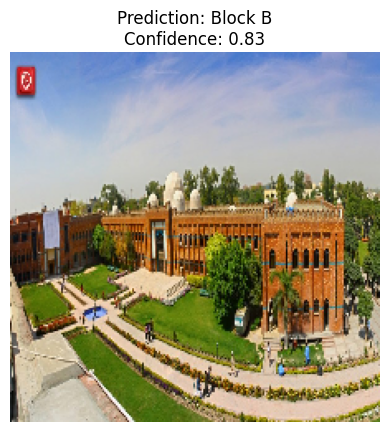

In [16]:
from tensorflow.keras.preprocessing import image
import numpy as np 
import matplotlib.pyplot as plt

# Get class names
# class_names = list(train_generator.class_indices.keys())
# print(f"Class names: {class_names}")
class_names = ['Block A', 'Block B', 'Block C', 'Block D', 'Block E', 'IEEE Office', 'NB']
def predict_landmark(img_path):
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) / 255.0

    pred = model.predict(img_array)
    pred_class = class_names[np.argmax(pred)]
    confidence = np.max(pred)

    plt.imshow(img)
    plt.title(f"Prediction: {pred_class}\nConfidence: {confidence:.2f}")
    plt.axis('off')
    return pred_class

# testing
test_image = 'Fast-Lahore.jpg'
predict_landmark(test_image)